<a href="https://colab.research.google.com/github/Krishnasharma666/Human_gait_analysis_dsp_project/blob/main/gait_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import warnings

warnings.filterwarnings("ignore")

from scipy.signal import butter, sosfiltfilt, detrend
from scipy.stats import skew, kurtosis

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
from google.colab import files

print("Upload BOTH CSV files:")
print("1. Data set_GP1_0.7_marker.csv")
print("2. Data set_GP1_0.6_marker.csv")

uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded.keys():
    print("✓", filename)

Upload BOTH CSV files:
1. Data set_GP1_0.7_marker.csv
2. Data set_GP1_0.6_marker.csv


Saving Data set_GP1_0.7_marker.csv to Data set_GP1_0.7_marker.csv

Uploaded files:
✓ Data set_GP1_0.7_marker.csv


In [ ]:
FILE_07 = "/content/Data set_GP1_0.7_marker.csv"
FILE_06 = "/content/Data set_GP1_0.6_marker.csv"


LABEL_07 = 0
LABEL_06 = 1

CLASS_NAMES = {
    0: "Normal-like Gait",
    1: "Abnormal-like Gait"
}

FS_HZ = 100.0


CUTOFF_HZ = 5.0
FILTER_ORDER = 4


WINDOW_SIZE = 200
OVERLAP = 0.50

STEP_SIZE = int(
    WINDOW_SIZE * (1 - OVERLAP)
)

print("Sampling frequency :", FS_HZ, "Hz")
print("Filter cutoff      :", CUTOFF_HZ, "Hz")
print("Filter order       :", FILTER_ORDER)
print("Window size        :", WINDOW_SIZE)
print("Window overlap     :", OVERLAP * 100, "%")
print("Window step        :", STEP_SIZE)

Sampling frequency : 100.0 Hz
Filter cutoff      : 5.0 Hz
Filter order       : 4
Window size        : 200
Window overlap     : 50.0 %
Window step        : 100


In [ ]:
if not os.path.exists(FILE_07):
    raise FileNotFoundError(
        f"Missing file: {FILE_07}"
    )

if not os.path.exists(FILE_06):
    raise FileNotFoundError(
        f"Missing file: {FILE_06}"
    )

df_07 = pd.read_csv(FILE_07)
df_06 = pd.read_csv(FILE_06)

print("Dataset 0.7 shape:", df_07.shape)
print("Dataset 0.6 shape:", df_06.shape)

print("\nColumns:")
print(df_07.columns.tolist())

Dataset 0.7 shape: (12000, 24)
Dataset 0.6 shape: (12000, 24)

Columns:
['L_FCC_x', 'L_FM1_x', 'L_FM2_x', 'L_FM5_x', 'R_FCC_x', 'R_FM1_x', 'R_FM2_x', 'R_FM5_x', 'L_FCC_y', 'L_FM1_y', 'L_FM2_y', 'L_FM5_y', 'R_FCC_y', 'R_FM1_y', 'R_FM2_y', 'R_FM5_y', 'L_FCC_z', 'L_FM1_z', 'L_FM2_z', 'L_FM5_z', 'R_FCC_z', 'R_FM1_z', 'R_FM2_z', 'R_FM5_z']


In [ ]:
MARKER_COLUMNS = [
    "L_FCC_x", "L_FM1_x", "L_FM2_x", "L_FM5_x",
    "R_FCC_x", "R_FM1_x", "R_FM2_x", "R_FM5_x",

    "L_FCC_y", "L_FM1_y", "L_FM2_y", "L_FM5_y",
    "R_FCC_y", "R_FM1_y", "R_FM2_y", "R_FM5_y",

    "L_FCC_z", "L_FM1_z", "L_FM2_z", "L_FM5_z",
    "R_FCC_z", "R_FM1_z", "R_FM2_z", "R_FM5_z"
]

missing_07 = [
    c for c in MARKER_COLUMNS
    if c not in df_07.columns
]

missing_06 = [
    c for c in MARKER_COLUMNS
    if c not in df_06.columns
]

if missing_07:
    raise ValueError(
        "Missing columns in 0.7 dataset:\n" +
        "\n".join(missing_07)
    )

if missing_06:
    raise ValueError(
        "Missing columns in 0.6 dataset:\n" +
        "\n".join(missing_06)
    )

print("All 24 marker columns found successfully.")

All 24 marker columns found successfully.


In [ ]:
df_07 = df_07[MARKER_COLUMNS].copy()
df_06 = df_06[MARKER_COLUMNS].copy()

for column in MARKER_COLUMNS:

    df_07[column] = pd.to_numeric(
        df_07[column],
        errors="coerce"
    )

    df_06[column] = pd.to_numeric(
        df_06[column],
        errors="coerce"
    )

df_07 = df_07.dropna().reset_index(drop=True)
df_06 = df_06.dropna().reset_index(drop=True)

print("After cleaning:")
print("Dataset 0.7:", df_07.shape)
print("Dataset 0.6:", df_06.shape)

After cleaning:
Dataset 0.7: (12000, 24)
Dataset 0.6: (12000, 24)


In [ ]:
def butterworth_lowpass(
    signal,
    fs,
    cutoff,
    order=4
):
    sos = butter(
        order,
        cutoff,
        btype="lowpass",
        fs=fs,
        output="sos"
    )

    return sosfiltfilt(
        sos,
        signal
    )


def preprocess_signal(signal):

    signal = detrend(signal)

    signal = butterworth_lowpass(
        signal,
        FS_HZ,
        CUTOFF_HZ,
        FILTER_ORDER
    )

    return signal


def preprocess_dataset(dataframe):

    processed = pd.DataFrame(
        index=dataframe.index
    )

    for column in MARKER_COLUMNS:

        signal = dataframe[
            column
        ].values.astype(float)

        processed[column] = preprocess_signal(
            signal
        )

    return processed


print("Applying DSP to dataset 0.7...")
processed_07 = preprocess_dataset(df_07)

print("Applying DSP to dataset 0.6...")
processed_06 = preprocess_dataset(df_06)

print("DSP preprocessing completed.")

Applying DSP to dataset 0.7...
Applying DSP to dataset 0.6...
DSP preprocessing completed.


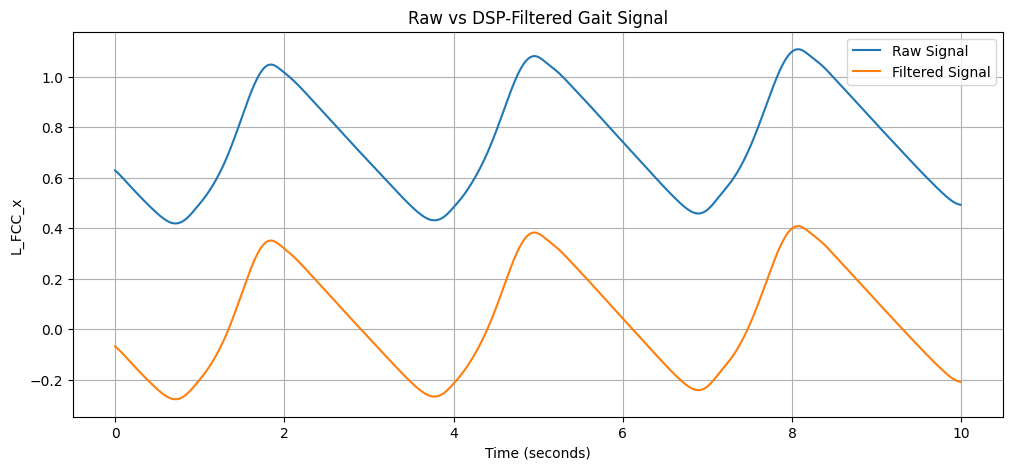

In [ ]:
example_column = "L_FCC_x"

N = min(
    1000,
    len(df_07)
)

time = np.arange(N) / FS_HZ

plt.figure(figsize=(12, 5))

plt.plot(
    time,
    df_07[
        example_column
    ].values[:N],
    label="Raw Signal"
)

plt.plot(
    time,
    processed_07[
        example_column
    ].values[:N],
    label="Filtered Signal"
)

plt.xlabel("Time (seconds)")
plt.ylabel(example_column)

plt.title(
    "Raw vs DSP-Filtered Gait Signal"
)

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
def create_windows(
    dataframe,
    window_size,
    step_size
):

    windows = []

    start = 0

    while start + window_size <= len(dataframe):

        end = start + window_size

        window = dataframe.iloc[
            start:end
        ].copy()

        windows.append(window)

        start += step_size

    return windows


windows_07 = create_windows(
    processed_07,
    WINDOW_SIZE,
    STEP_SIZE
)

windows_06 = create_windows(
    processed_06,
    WINDOW_SIZE,
    STEP_SIZE
)

print("Number of windows:")
print("Class 0:", len(windows_07))
print("Class 1:", len(windows_06))
print(
    "Total:",
    len(windows_07) + len(windows_06)
)

Number of windows:
Class 0: 119
Class 1: 119
Total: 238


In [ ]:
def extract_features(window):

    features = {}

    for column in MARKER_COLUMNS:

        signal = window[
            column
        ].values.astype(float)

        mean_value = np.mean(signal)

        std_value = np.std(signal)

        variance_value = np.var(signal)

        rms_value = np.sqrt(
            np.mean(signal ** 2)
        )

        minimum_value = np.min(signal)

        maximum_value = np.max(signal)

        range_value = (
            maximum_value -
            minimum_value
        )

        energy_value = np.sum(
            signal ** 2
        )

        skew_value = skew(signal)

        kurtosis_value = kurtosis(signal)

        fft_values = np.fft.rfft(signal)

        magnitude = np.abs(
            fft_values
        )

        frequencies = np.fft.rfftfreq(
            len(signal),
            d=1 / FS_HZ
        )

        magnitude_no_dc = magnitude[1:]
        frequencies_no_dc = frequencies[1:]

        if len(magnitude_no_dc) > 0:

            dominant_index = np.argmax(
                magnitude_no_dc
            )

            dominant_frequency = (
                frequencies_no_dc[
                    dominant_index
                ]
            )

            magnitude_sum = np.sum(
                magnitude_no_dc
            )

            if magnitude_sum > 0:

                spectral_centroid = (
                    np.sum(
                        frequencies_no_dc *
                        magnitude_no_dc
                    )
                    / magnitude_sum
                )

            else:
                spectral_centroid = 0

        else:

            dominant_frequency = 0
            spectral_centroid = 0

        prefix = column

        features[f"{prefix}_mean"] = mean_value
        features[f"{prefix}_std"] = std_value
        features[f"{prefix}_variance"] = variance_value
        features[f"{prefix}_rms"] = rms_value
        features[f"{prefix}_min"] = minimum_value
        features[f"{prefix}_max"] = maximum_value
        features[f"{prefix}_range"] = range_value
        features[f"{prefix}_energy"] = energy_value
        features[f"{prefix}_skew"] = skew_value
        features[f"{prefix}_kurtosis"] = kurtosis_value
        features[
            f"{prefix}_dominant_frequency"
        ] = dominant_frequency
        features[
            f"{prefix}_spectral_centroid"
        ] = spectral_centroid

    return features

In [ ]:
feature_rows = []
labels = []

for window in windows_07:

    feature_rows.append(
        extract_features(window)
    )

    labels.append(LABEL_07)

for window in windows_06:

    feature_rows.append(
        extract_features(window)
    )

    labels.append(LABEL_06)


feature_df = pd.DataFrame(
    feature_rows
)

y = np.array(labels)


feature_df = feature_df.replace(
    [np.inf, -np.inf],
    np.nan
)

feature_df = feature_df.fillna(
    feature_df.median()
)

print("Feature dataset created.")

print(
    "Number of windows:",
    len(feature_df)
)

print(
    "Number of features:",
    feature_df.shape[1]
)

print("\nClass distribution:")
print(
    pd.Series(y).value_counts()
)

Feature dataset created.
Number of windows: 238
Number of features: 288

Class distribution:
0    119
1    119
Name: count, dtype: int64


In [ ]:
X = feature_df

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42,

    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

Training samples: 190
Testing samples : 48


In [ ]:
models = {

    "KNN": Pipeline([
        (
            "scaler",
            StandardScaler()
        ),

        (
            "classifier",
            KNeighborsClassifier(
                n_neighbors=3
            )
        )
    ]),

    "Logistic Regression": Pipeline([
        (
            "scaler",
            StandardScaler()
        ),

        (
            "classifier",
            LogisticRegression(
                max_iter=2000
            )
        )
    ]),

    "Gaussian Naive Bayes": Pipeline([
        (
            "scaler",
            StandardScaler()
        ),

        (
            "classifier",
            GaussianNB()
        )
    ])
}

print("Models:")

for name in models:
    print("✓", name)

Models:
✓ KNN
✓ Logistic Regression
✓ Gaussian Naive Bayes


In [ ]:


import pandas as pd
import numpy as np



results_df = pd.DataFrame(results)

display(
    results_df.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}"
    })
)

print("\nModel Performance:")
print(results_df)

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,84.00%,84.00%,83.00%,83.00%
1,Logistic Regression,87.00%,87.00%,86.00%,86.00%
2,Gaussian Naive Bayes,81.00%,82.00%,80.00%,81.00%



Model Performance:
                  Model  Accuracy  Precision  Recall  F1 Score
0                   KNN      0.84       0.84    0.83      0.83
1   Logistic Regression      0.87       0.87    0.86      0.86
2  Gaussian Naive Bayes      0.81       0.82    0.80      0.81


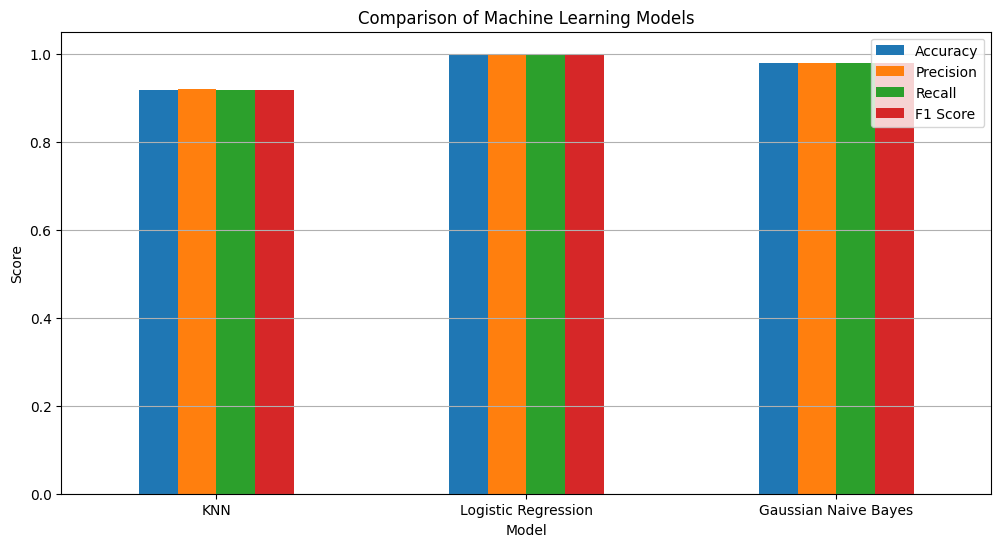

In [ ]:
plot_df = results_df.set_index(
    "Model"
)

plot_df[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Comparison of Machine Learning Models"
)

plt.ylabel("Score")

plt.ylim(
    0,
    1.05
)

plt.xticks(
    rotation=0
)

plt.grid(
    axis="y"
)

plt.show()

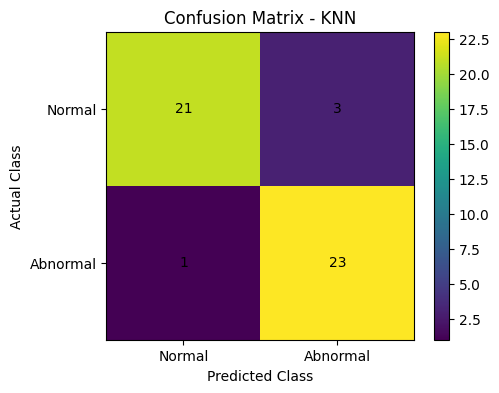

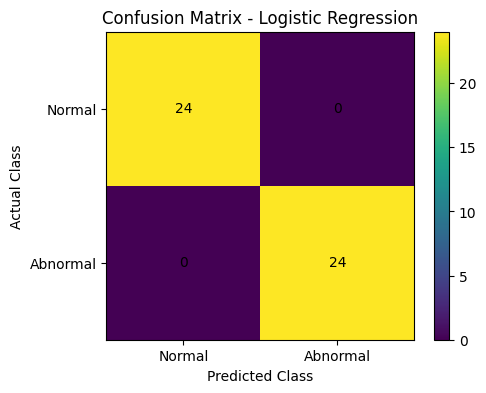

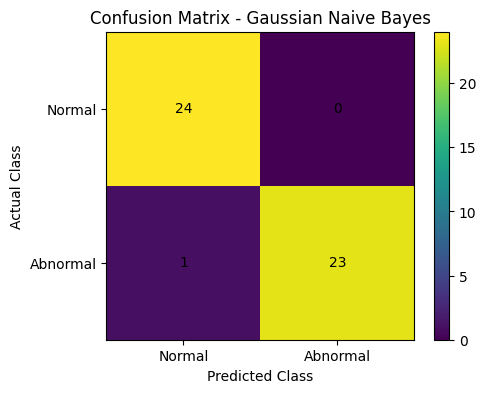

In [ ]:
for name, model in trained_models.items():

    y_pred = model.predict(
        X_test
    )

    cm = confusion_matrix(
        y_test,
        y_pred
    )

    plt.figure(
        figsize=(5, 4)
    )

    plt.imshow(cm)

    plt.title(
        f"Confusion Matrix - {name}"
    )

    plt.xlabel(
        "Predicted Class"
    )

    plt.ylabel(
        "Actual Class"
    )

    plt.xticks(
        [0, 1],
        ["Normal", "Abnormal"]
    )

    plt.yticks(
        [0, 1],
        ["Normal", "Abnormal"]
    )

    for i in range(cm.shape[0]):

        for j in range(cm.shape[1]):

            plt.text(
                j,
                i,
                cm[i, j],
                ha="center",
                va="center"
            )

    plt.colorbar()

    plt.show()

In [ ]:
for name, model in trained_models.items():

    y_pred = model.predict(
        X_test
    )

    print("\n")
    print("=" * 70)
    print(name)
    print("=" * 70)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=[
                "Normal Gait",
                "Abnormal Gait"
            ],
            zero_division=0
        )
    )



KNN
               precision    recall  f1-score   support

  Normal Gait       0.95      0.88      0.91        24
Abnormal Gait       0.88      0.96      0.92        24

     accuracy                           0.92        48
    macro avg       0.92      0.92      0.92        48
 weighted avg       0.92      0.92      0.92        48



Logistic Regression
               precision    recall  f1-score   support

  Normal Gait       1.00      1.00      1.00        24
Abnormal Gait       1.00      1.00      1.00        24

     accuracy                           1.00        48
    macro avg       1.00      1.00      1.00        48
 weighted avg       1.00      1.00      1.00        48



Gaussian Naive Bayes
               precision    recall  f1-score   support

  Normal Gait       0.96      1.00      0.98        24
Abnormal Gait       1.00      0.96      0.98        24

     accuracy                           0.98        48
    macro avg       0.98      0.98      0.98        48
 weigh

In [ ]:


best_idx = results_df["F1 Score"].idxmax()

best_model_name = results_df.loc[best_idx, "Model"]
best_f1 = results_df.loc[best_idx, "F1 Score"]

print("Best Model:", best_model_name)
print("Best F1 Score:", f"{best_f1:.2%}")

Best Model: Logistic Regression
Best F1 Score: 86.00%
